# Exercice 2 : Classification - Prédiction de la survie sur le Titanic

**Objectif:** Prédire si un passager a survécu (1) ou non (0).

**Dataset:** Titanic - Machine Learning from Disaster (Kaggle)

In [1]:
# Importation des bibliotheques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Bibliothèques importées avec succès!")

Bibliothèques importées avec succès!


In [2]:
# Chargement du dataset
data = pd.read_csv('../data/titanic.csv')

# Afficher les premieres lignes
print("=== Premières lignes ===")
print(data.head())

# Informations
print("\n=== Informations ===")
print(data.info())

# Valeurs manquantes
print("\n=== Valeurs manquantes ===")
print(data.isnull().sum())

=== Premières lignes ===
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8

In [ ]:
# Selectionner les colonnes utiles
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

print("Colonnes sélectionnées!")
print(data.head())

Colonnes sélectionnées!
   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


In [4]:
# Remplir l'age manquant par la mediane
data['Age'] = data['Age'].fillna(data['Age'].median())

# Remplir Embarked par la valeur la plus frequente
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# Verifier qu'il n'y a plus de valeurs manquantes
print("Valeurs manquantes après nettoyage:")
print(data.isnull().sum())

Valeurs manquantes après nettoyage:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [5]:
# Encodage: convertir 'Sex' et 'Embarked' en chiffres
le = LabelEncoder()
data['Sex'] = le.fit_transform(data['Sex'])           # male=1, female=0
data['Embarked'] = le.fit_transform(data['Embarked'])  # C=0, Q=1, S=2

print("Encodage terminé!")
print(data.head())

Encodage terminé!
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


In [6]:
# Separation X et y
X = data.drop('Survived', axis=1)
y = data['Survived']

# Train/Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (712, 7)
X_test: (179, 7)
y_train: (712,)
y_test: (179,)


In [7]:
# Modele 1: Regression Logistique
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

# Predictions
y_pred_log = log_model.predict(X_test)

# Evaluation
acc_log = accuracy_score(y_test, y_pred_log)
print("=== LogisticRegression ===")
print(f"Accuracy: {acc_log:.4f}")

=== LogisticRegression ===
Accuracy: 0.8101


In [8]:
# Modele 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluation
acc_rf = accuracy_score(y_test, y_pred_rf)
print("=== RandomForest ===")
print(f"Accuracy: {acc_rf:.4f}")

=== RandomForest ===
Accuracy: 0.8212


In [9]:
# Rapport de classification 
print("=== Classification Report - RandomForest ===")
print(classification_report(y_test, y_pred_rf, target_names=['Non Survécu', 'Survécu']))

=== Classification Report - RandomForest ===
              precision    recall  f1-score   support

 Non Survécu       0.83      0.88      0.85       105
     Survécu       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



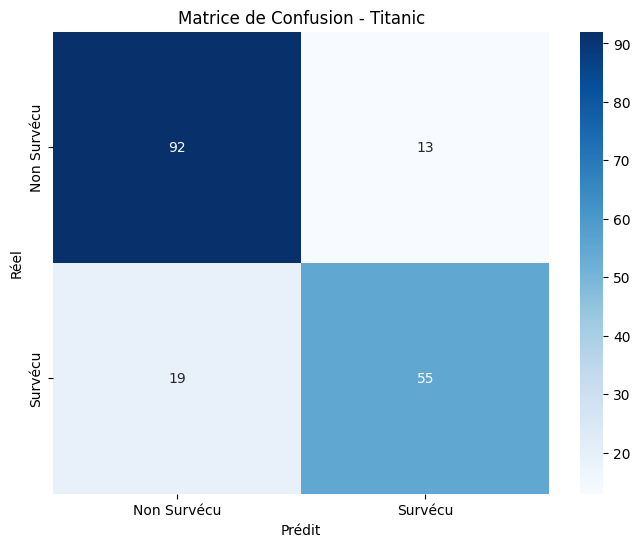

In [10]:
# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non Survécu', 'Survécu'],
            yticklabels=['Non Survécu', 'Survécu'])
plt.title('Matrice de Confusion - Titanic')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

In [11]:
# Comparaison
comparison = pd.DataFrame({
    'Modèle': ['LogisticRegression', 'RandomForest'],
    'Accuracy': [acc_log, acc_rf]
})

print("=== Comparaison des Modèles ===")
print(comparison.to_string(index=False))

=== Comparaison des Modèles ===
            Modèle  Accuracy
LogisticRegression  0.810056
      RandomForest  0.821229


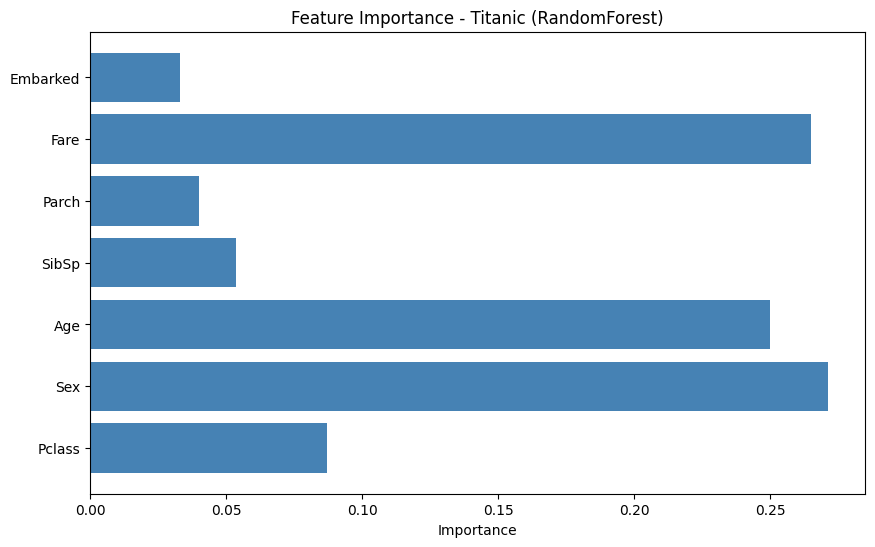

Pclass: 0.0870
Sex: 0.2714
Age: 0.2500
SibSp: 0.0537
Parch: 0.0399
Fare: 0.2650
Embarked: 0.0330


In [12]:
# Feature Importance
features = X.columns
importances = rf_model.feature_importances_

plt.figure(figsize=(10, 6))
plt.barh(features, importances, color='steelblue')
plt.xlabel('Importance')
plt.title('Feature Importance - Titanic (RandomForest)')
plt.show()

# Affichage
for feat, imp in zip(features, importances):
    print(f"{feat}: {imp:.4f}")

## Conclusion - Exercice 2

### Résultats:
| Modèle | Accuracy |
| :--- | :--- |
| LogisticRegression | 0.810056|
| RandomForest | 0.821229 |

### Interprétation:
- **RandomForest** est légèrement plus performant que **LogisticRegression**.
- Les variables les plus importantes pour la prédiction sont : **Sex**, **Fare**, **Age**.
- Le modèle prédit correctement environ 83% des cas.

### Améliorations possibles:
- Feature engineering (créer des variables dérivées comme "FamilySize")
- Tester d'autres modèles (XGBoost, GradientBoosting)
- Ajuster les hyperparamètres (GridSearchCV)